In [2]:
import fastf1
import fastf1.plotting
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
from scipy.stats import linregress
import seaborn as sns




In [3]:
# Configures matplotlib to use styling by FastF1
fastf1.plotting.setup_mpl(color_scheme='fastf1', misc_mpl_mods=False)

year =2024
gp = 'Spain'
session_type = 'R'

session = fastf1.get_session(year, gp, session_type)
session.load()

/home/iec/anaconda3/envs/f1env/lib/python3.14/site-packages/fastf1/plotting/_plotting.py:56: FutureWarning: The `misc_mpl_mods` argument was dropped from `.setup_mpl()` in version 3.6.0 and has no effect anymore. It will be removed in a future version of FastF1.
  warnings.warn(
req         WARNING 	DEFAULT CACHE ENABLED! (197.33 MB) /home/iec/.cache/fastf1
core           INFO 	Loading data for Spanish Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Driver 1 completed the race distance 00:00.015000 before the recorded end of the sessio

In [4]:
laps = session.laps.copy()

laps["Season"] = year
laps["Event"] = session.event['EventName']
laps["Round"] = session.event['RoundNumber']
laps["SessionType"] = session_type






In [5]:
laps.info()

<class 'fastf1.core.Laps'>
RangeIndex: 1310 entries, 0 to 1309
Data columns (total 35 columns):
 #   Column              Non-Null Count  Dtype          
---  ------              --------------  -----          
 0   Time                1310 non-null   timedelta64[ns]
 1   Driver              1310 non-null   object         
 2   DriverNumber        1310 non-null   object         
 3   LapTime             1310 non-null   timedelta64[ns]
 4   LapNumber           1310 non-null   float64        
 5   Stint               1310 non-null   float64        
 6   PitOutTime          43 non-null     timedelta64[ns]
 7   PitInTime           42 non-null     timedelta64[ns]
 8   Sector1Time         1290 non-null   timedelta64[ns]
 9   Sector2Time         1310 non-null   timedelta64[ns]
 10  Sector3Time         1310 non-null   timedelta64[ns]
 11  Sector1SessionTime  1285 non-null   timedelta64[ns]
 12  Sector2SessionTime  1310 non-null   timedelta64[ns]
 13  Sector3SessionTime  1310 non-null   timedelt

In [6]:
time_columns = [
    "LapTime",
    "Sector1Time",
    "Sector2Time",
    "Sector3Time"
]
for column in time_columns:
    laps[f"{column}_seconds"] = laps[column].dt.total_seconds()

In [7]:
laps.describe()

,Time,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,Sector3Time,Sector1SessionTime,...,TyreLife,LapStartTime,LapStartDate,Position,Season,Round,LapTime_seconds,Sector1Time_seconds,Sector2Time_seconds,Sector3Time_seconds
count,1310,1310,1310.000000,1310.000000,43,42,1290,1310,1310,1285,...,1310.000000,1310,1310,1310.000000,1310.0,1310.0,1310.000000,1290.000000,1310.000000,1310.000000
mean,0 days 01:42:26.667640458,0 days 00:01:21.474285496,33.252672,2.208397,0 days 01:34:29.439767441,0 days 01:35:00.239928571,0 days 00:00:24.408948062,0 days 00:00:32.546877862,0 days 00:00:24.436202290,0 days 01:42:10.254726848,...,12.595420,0 days 01:41:05.189904580,2024-06-23 13:47:22.507904256,10.454962,2024.0,10.0,81.474285,24.408948,32.546878,24.436202
min,0 days 00:58:19.889000,0 days 00:01:17.115000,1.000000,1.000000,0 days 00:57:07.090000,0 days 01:09:30.287000,0 days 00:00:22.564000,0 days 00:00:31.195000,0 days 00:00:23.246000,0 days 00:58:44.162000,...,1.000000,0 days 00:56:57.095000,2024-06-23 13:03:14.413000,1.000000,2024.0,10.0,77.115000,22.564000,31.195000,23.246000
25%,0 days 01:20:24.251750,0 days 00:01:19.721250,17.000000,2.000000,0 days 01:17:42.059000,0 days 01:17:40.154750,0 days 00:00:23.480000,0 days 00:00:32.142000,0 days 00:00:24.011000,0 days 01:20:39.666000,...,7.000000,0 days 01:19:00.682000,2024-06-23 13:25:18,5.000000,2024.0,10.0,79.721250,23.480000,32.142000,24.011000
50%,0 days 01:42:33.346000,0 days 00:01:20.908000,33.000000,2.000000,0 days 01:34:50.136000,0 days 01:35:04.716000,0 days 00:00:23.795000,0 days 00:00:32.529500,0 days 00:00:24.328000,0 days 01:42:10.307000,...,12.000000,0 days 01:41:12.291000,2024-06-23 13:47:29.608999936,10.000000,2024.0,10.0,80.908000,23.795000,32.529500,24.328000
75%,0 days 02:04:40.850500,0 days 00:01:21.736250,50.000000,3.000000,0 days 01:51:31.229500,0 days 01:52:11.210500,0 days 00:00:24.059000,0 days 00:00:32.890250,0 days 00:00:24.633500,0 days 02:04:02.172000,...,18.000000,0 days 02:03:20.929750,2024-06-23 14:09:38.247749888,15.000000,2024.0,10.0,81.736250,24.059000,32.890250,24.633500
max,0 days 02:26:31.763000,0 days 00:01:47.447000,66.000000,4.000000,0 days 02:03:57.454000,0 days 02:03:36.017000,0 days 00:00:50.157000,0 days 00:00:41.310000,0 days 00:00:29.419000,0 days 02:25:34.328000,...,37.000000,0 days 02:25:10.637000,2024-06-23 14:31:27.955000,20.000000,2024.0,10.0,107.447000,50.157000,41.310000,29.419000
std,0 days 00:25:41.313634114,0 days 00:00:03.714862411,18.917847,0.831075,0 days 00:18:43.633857449,0 days 00:18:00.809702938,0 days 00:00:03.488936599,0 days 00:00:00.644622377,0 days 00:00:00.832799798,0 days 00:25:15.243268157,...,7.407158,0 days 00:25:42.391673842,NaN,5.762345,0.0,0.0,3.714862,3.488937,0.644622,0.832800


In [8]:
weather = session.weather_data.copy()

laps = laps.sort_values("Time")
weather = weather.sort_values("Time")

laps = pd.merge_asof(
    laps,
    weather,
    on="Time",
    direction="backward"
)

In [9]:
laps["ValidModelLap"] = (
    laps["LapTime_seconds"].notna() &
    laps["Compound"].notna() &
    laps["TyreLife"].notna() &
    laps["PitInTime"].isna() &
    laps["PitOutTime"].isna() &
    (~laps["Deleted"]) &
    laps["IsAccurate"] &
    (laps["TrackStatus"] == "1")
)

In [10]:
laps["ValidModelLap"].value_counts()

ValidModelLap
True     1192
False     118
Name: count, dtype: int64

In [11]:
drivers = laps["Driver"].unique()

In [12]:
driver = 'VER'

driver_laps = laps[
    (laps["Driver"] == driver) &
    laps["LapTime_seconds"].notna() &
    laps["PitInTime"].isna() &
    laps["PitOutTime"].isna() &
    laps["ValidModelLap"] 
].copy()


In [13]:
driver_laps.select_dtypes(include=[np.number]).columns


Index(['Time', 'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime',
       'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime',
       'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2',
       'SpeedFL', 'SpeedST', 'TyreLife', 'LapStartTime', 'Position', 'Season',
       'Round', 'LapTime_seconds', 'Sector1Time_seconds',
       'Sector2Time_seconds', 'Sector3Time_seconds', 'AirTemp', 'Humidity',
       'Pressure', 'TrackTemp', 'WindDirection', 'WindSpeed'],
      dtype='object')

In [14]:
clean_laps = laps[laps["ValidModelLap"]].copy()

In [15]:
clean_laps["ValidModelLap"].value_counts(dropna=False)

ValidModelLap
True    1192
Name: count, dtype: int64

In [16]:
numeric_corr = (
    clean_laps.select_dtypes(include="number")
    .corr(method="spearman")["LapTime_seconds"]
    .sort_values()
)

display(numeric_corr)

SpeedFL               -0.613850
Stint                 -0.613087
LapNumber             -0.606291
LapStartTime          -0.596013
Sector2SessionTime    -0.595561
Sector3SessionTime    -0.595487
Time                  -0.595487
SpeedI1               -0.594857
Sector1SessionTime    -0.590333
SpeedI2               -0.543542
TyreLife              -0.039359
WindDirection         -0.031802
SpeedST                0.001325
TrackTemp              0.022793
AirTemp                0.059506
WindSpeed              0.191046
Humidity               0.336564
Pressure               0.338600
Position               0.461023
Sector1Time            0.873671
Sector1Time_seconds    0.873671
Sector3Time_seconds    0.940873
Sector3Time            0.940873
Sector2Time            0.953247
Sector2Time_seconds    0.953247
LapTime                1.000000
LapTime_seconds        1.000000
PitOutTime                  NaN
PitInTime                   NaN
Season                      NaN
Round                       NaN
Name: La

In [17]:
stint_relationships = (
    clean_laps.groupby(["Driver", "Stint", "Compound"])
    .filter(lambda group: len(group) >= 5)
    .groupby(["Driver", "Stint", "Compound"])
    .apply(
        lambda group: pd.Series({
            "NumLaps": len(group),
            "StartTyreLife": group["TyreLife"].min(),
            "EndTyreLife": group["TyreLife"].max(),
            "LapTimeCorrelation":
                group["TyreLife"].corr(
                    group["LapTime_seconds"],
                    method="spearman"
                ),
            "LapTimeChange":
                group["LapTime_seconds"].iloc[-1]
                - group["LapTime_seconds"].iloc[0],
        }),
        include_groups=False
    )
    .reset_index()
)

display(stint_relationships.sort_values("LapTimeCorrelation"))

,Driver,Stint,Compound,NumLaps,StartTyreLife,EndTyreLife,LapTimeCorrelation,LapTimeChange
39,RIC,3.0,HARD,22.0,2.0,23.0,-0.642010,-1.507
37,RIC,1.0,SOFT,14.0,2.0,15.0,-0.586813,-0.288
49,STR,1.0,SOFT,15.0,2.0,16.0,-0.528571,-0.632
46,SAR,1.0,SOFT,11.0,2.0,13.0,-0.363636,-0.508
21,MAG,1.0,SOFT,8.0,2.0,9.0,-0.333333,-0.878
...,...,...,...,...,...,...,...,...
47,SAR,2.0,MEDIUM,18.0,2.0,19.0,0.843137,2.035
20,LEC,3.0,SOFT,18.0,5.0,22.0,0.845201,1.320
12,HAM,1.0,SOFT,14.0,5.0,18.0,0.854945,1.383
10,GAS,2.0,MEDIUM,22.0,2.0,23.0,0.865613,1.293


findfont: Failed to find font weight medium, now using 400.


0.6870129870129871


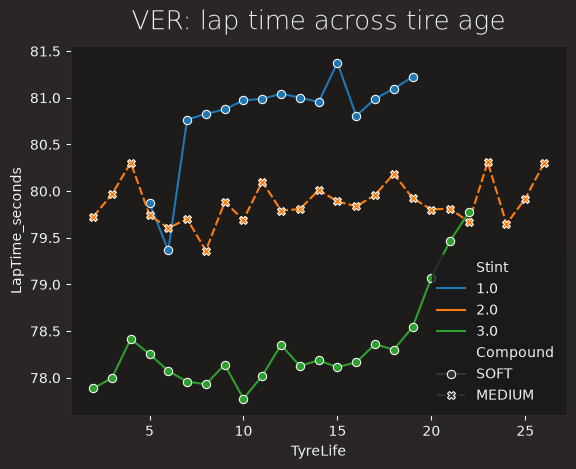

In [18]:
driver = "VER"

driver_data = clean_laps[clean_laps["Driver"] == driver]

stint = 3

sample = driver_data[
    (driver_data["Driver"] == driver)
    & (driver_data["Stint"] == stint)
].sort_values("TyreLife")

print(
    sample["TyreLife"].corr(
        sample["LapTime_seconds"],
        method="spearman"
    )
)

sns.lineplot(
    data=driver_data,
    x="TyreLife",
    y="LapTime_seconds",
    hue="Stint",
    style="Compound",
    markers=True,
    palette=sns.color_palette("tab10", n_colors=driver_data["Stint"].nunique())
)

plt.title(f"{driver}: lap time across tire age")
plt.show()

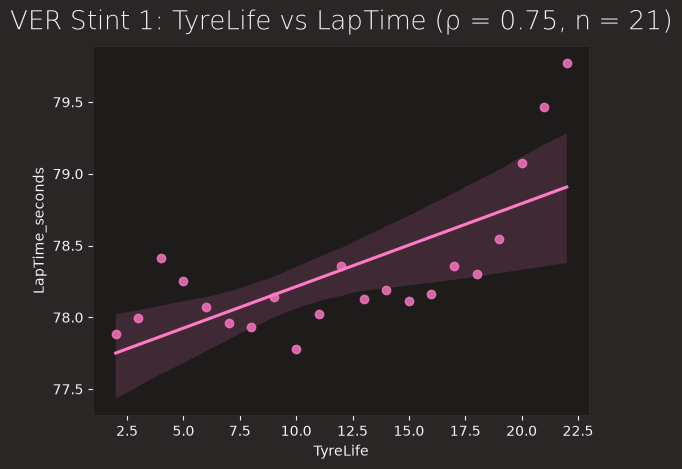

In [19]:
sns.regplot(
    data=sample,
    x="TyreLife",
    y="LapTime_seconds",
    ci=95
)

plt.title(
    f"VER Stint 1: "
    f"TyreLife vs LapTime (ρ = 0.75, n = {len(sample)})"
)
plt.show()

In [20]:
from scipy.stats import linregress

result = linregress(
    sample["TyreLife"],
    sample["LapTime_seconds"]
)

print("Slope:", result.slope, "seconds per tire lap")
print("R²:", result.rvalue ** 2)
print("p-value:", result.pvalue)

Slope: 0.057831168831169004 seconds per tire lap
R²: 0.49203325930125286
p-value: 0.0003952901312673079


In [21]:
clean_laps.groupby("Compound")[
    ["LapTime_seconds", "TyreLife"]
].agg(["count","mean","median","std"])

LapTime_seconds                               TyreLife             \
                   count       mean   median       std    count       mean   
Compound                                                                     
HARD                 345  80.206988  79.8670  1.169243      345  15.536232   
MEDIUM               395  80.787577  80.8490  0.998993      395  12.551899   
SOFT                 452  80.731024  81.1515  1.544296      452  11.274336   

                           
         median       std  
Compound                   
HARD       15.0  8.571823  
MEDIUM     12.0  6.664872  
SOFT       11.0  5.537612

In [22]:
from scipy.stats import linregress
import pandas as pd

records = []

for (driver, stint, compound), group in clean_laps.groupby(["Driver", "Stint", "Compound"]):
    group = group.sort_values("TyreLife")
    
    if len(group) < 5 or group["TyreLife"].nunique() < 3:
        continue  # Skip groups with insufficient data
    
    result = linregress(
        group["TyreLife"],
        group["LapTime_seconds"]
    )
    
    records.append({
        "Driver": driver,
        "Team": group["Team"].iloc[0],
        "Stint": stint,
        "Compound": compound,
        "NumLaps": len(group),
        "SlopeSecondsPerLap": result.slope,
        "Correlation": result.rvalue,
    })
    
stint_slopes = pd.DataFrame(records)

In [23]:
stint_slopes.sort_values("SlopeSecondsPerLap", ascending=False)

,Driver,Team,Stint,Compound,NumLaps,SlopeSecondsPerLap,Correlation
7,BOT,Kick Sauber,2.0,SOFT,15,0.212843,0.924160
54,TSU,RB,3.0,HARD,15,0.188093,0.675957
52,TSU,RB,1.0,SOFT,6,0.113857,0.461651
47,SAR,Williams,2.0,MEDIUM,18,0.110264,0.873649
12,HAM,Mercedes,1.0,SOFT,14,0.094132,0.887471
...,...,...,...,...,...,...,...
2,ALB,Williams,3.0,SOFT,20,-0.038242,-0.262038
46,SAR,Williams,1.0,SOFT,11,-0.053558,-0.441445
21,MAG,Haas F1 Team,1.0,SOFT,8,-0.069988,-0.460666
37,RIC,RB,1.0,SOFT,14,-0.073609,-0.589352


In [24]:
stint_slopes.groupby("Team")[
    "SlopeSecondsPerLap"
].agg(["count", "mean", "median", "std"]).sort_values("mean", ascending=False)

,count,mean,median,std
Team,,,,
Mercedes,6,0.049302,0.049813,0.033103
Alpine,6,0.049270,0.061821,0.033536
Red Bull Racing,7,0.046946,0.057831,0.041524
Kick Sauber,6,0.041970,0.014530,0.088736
Ferrari,6,0.038289,0.026622,0.025991
Williams,6,0.032849,0.052097,0.065437
RB,7,0.023812,0.019116,0.101649
McLaren,6,0.018193,0.014078,0.027067
Haas F1 Team,6,0.010880,0.015560,0.044558


In [25]:
clean_laps.columns

Index(['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint',
       'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time',
       'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime',
       'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest',
       'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime',
       'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason',
       'FastF1Generated', 'IsAccurate', 'Season', 'Event', 'Round',
       'SessionType', 'LapTime_seconds', 'Sector1Time_seconds',
       'Sector2Time_seconds', 'Sector3Time_seconds', 'AirTemp', 'Humidity',
       'Pressure', 'Rainfall', 'TrackTemp', 'WindDirection', 'WindSpeed',
       'ValidModelLap'],
      dtype='object')

In [26]:
track_temp_analysis = clean_laps[["TrackTemp", "LapNumber"]].sort_values("LapNumber")

<Axes: xlabel='LapNumber'>

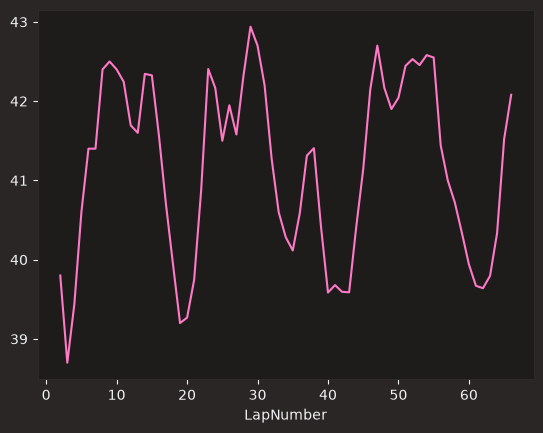

In [27]:
track_temp_analysis.groupby("LapNumber")["TrackTemp"].mean().plot()

In [28]:
clean_laps["TrackTemp"].corr(
    clean_laps["LapTime_seconds"],
    method="spearman"
)

np.float64(0.022792743451201965)

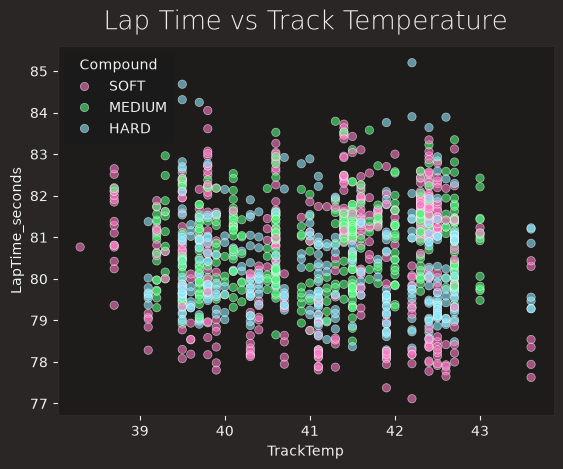

In [29]:
sns.scatterplot(
    data=clean_laps,
    x="TrackTemp",
    y="LapTime_seconds",
    hue="Compound",
    alpha=0.6
)

plt.title("Lap Time vs Track Temperature")
plt.show()

In [30]:
clean_laps.groupby(["Compound", "FreshTyre"])[
    "LapTime_seconds"
].agg(["count", "mean", "median", "std"])

count       mean   median       std
Compound FreshTyre                                     
HARD     False         46  79.952696  79.7215  0.987335
         True         299  80.246110  79.9270  1.191402
MEDIUM   False         42  81.165238  81.1955  0.442001
         True         353  80.742643  80.6420  1.036951
SOFT     False        218  80.120408  80.7220  1.509260
         True         234  81.299889  81.4780  1.349400

In [31]:
clean_laps.groupby(
    ["Driver", "Stint", "Compound", "FreshTyre"]
)["TyreLife"].min().reset_index().value_counts()

Driver  Stint  Compound  FreshTyre  TyreLife
ALB     1.0    MEDIUM    True       2.0         1
        2.0    SOFT      True       2.0         1
        3.0    SOFT      True       2.0         1
ALO     1.0    SOFT      True       2.0         1
        2.0    MEDIUM    False      3.0         1
                                               ..
VER     2.0    MEDIUM    True       2.0         1
        3.0    SOFT      True       2.0         1
ZHO     1.0    SOFT      True       2.0         1
        2.0    MEDIUM    True       2.0         1
        3.0    HARD      True       2.0         1
Name: count, Length: 62, dtype: int64

In [32]:
clean_laps.groupby("Compound")["SpeedI1"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
Compound,,,,
HARD,345,269.889855,271.0,8.663914
MEDIUM,395,265.463291,266.0,6.993147
SOFT,452,264.000000,264.0,9.072753


<Axes: xlabel='SpeedI1', ylabel='LapTime_seconds'>

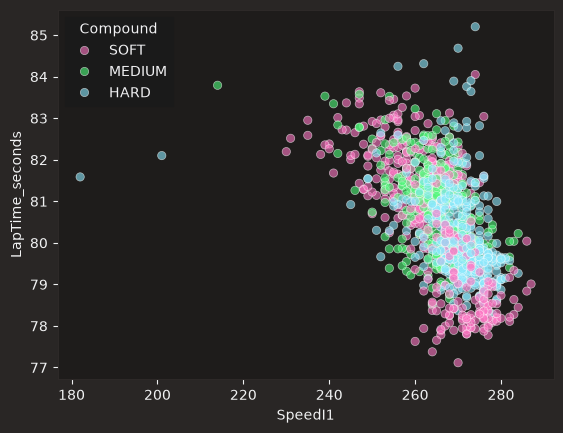

In [33]:
sns.scatterplot(
    data=clean_laps,
    x="SpeedI1",
    y="LapTime_seconds",
    hue="Compound",
    alpha=0.6
)

In [34]:
clean_laps = clean_laps.sort_values(["Driver", "Stint", "LapNumber"])

clean_laps["PreviousLapTime"] = (
    clean_laps.groupby(["Driver", "Stint"])["LapTime_seconds"]
    .shift(1)
)

In [35]:
laps.columns

Index(['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint',
       'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time',
       'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime',
       'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest',
       'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime',
       'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason',
       'FastF1Generated', 'IsAccurate', 'Season', 'Event', 'Round',
       'SessionType', 'LapTime_seconds', 'Sector1Time_seconds',
       'Sector2Time_seconds', 'Sector3Time_seconds', 'AirTemp', 'Humidity',
       'Pressure', 'Rainfall', 'TrackTemp', 'WindDirection', 'WindSpeed',
       'ValidModelLap'],
      dtype='object')

In [37]:
baseline_features = [
    "LapTime_seconds",
    "PreviousLapTime",
    "TyreLife",
    "Stint",
    "Compound",
    "FreshTyre",
    "Driver",
    "Team",
    "LapNumber",
    "Event",
]